/home/scrater/miniforge3/envs/spyglass/lib/python3.10/site-packages/datajoint/plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[2026-09-25 13:52:29,332][INFO]: DataJoint 0.14.6 connected to scrater@lmf-db.cin.ucsf.edu:3306
/home/scrater/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/spec/namespace.py:484: UserWarning: Schema conflict(s) detected in namespace 'ndx-fiber-photometry': 
 ndx-fiber-photometry defines OpticalFiber.model as an attribute (dtype: text) while the core schema defines it as a link to DeviceModel.
ndx-fiber-photometry defines ExcitationSource.model as an attribute (dtype: text) while the core schema defines it as a link to DeviceModel.
ndx-fiber-photometry defines Photodetector.model as an attribute (dtype: text) while the core 

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 1}: HexmazeNoStim


/home/scrater/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/spec/namespace.py:484: UserWarning: Schema conflict(s) detected in namespace 'ndx-optogenetics': 
 ndx-optogenetics defines ExcitationSource.model as a link to ExcitationSourceModel while the core schema defines it as a link to DeviceModel. ExcitationSourceModel is not a subtype of DeviceModel. 
ndx-optogenetics defines OpticalFiber.model as a link to OpticalFiberModel while the core schema defines it as a link to DeviceModel. OpticalFiberModel is not a subtype of DeviceModel.  
This may cause compatibility issues. Please update the extension version if possible or install an older version of the core schema that is compatible.
  self._check_namespace_conflicts(extension_ns_name=ns_name,
/home/scrater/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/camera_device 0/model
  warnings.warn('Path to Group altere

saved figures/ahead_behind/Vinnie20260813_ep5_block1_classic_d7c7a7.png


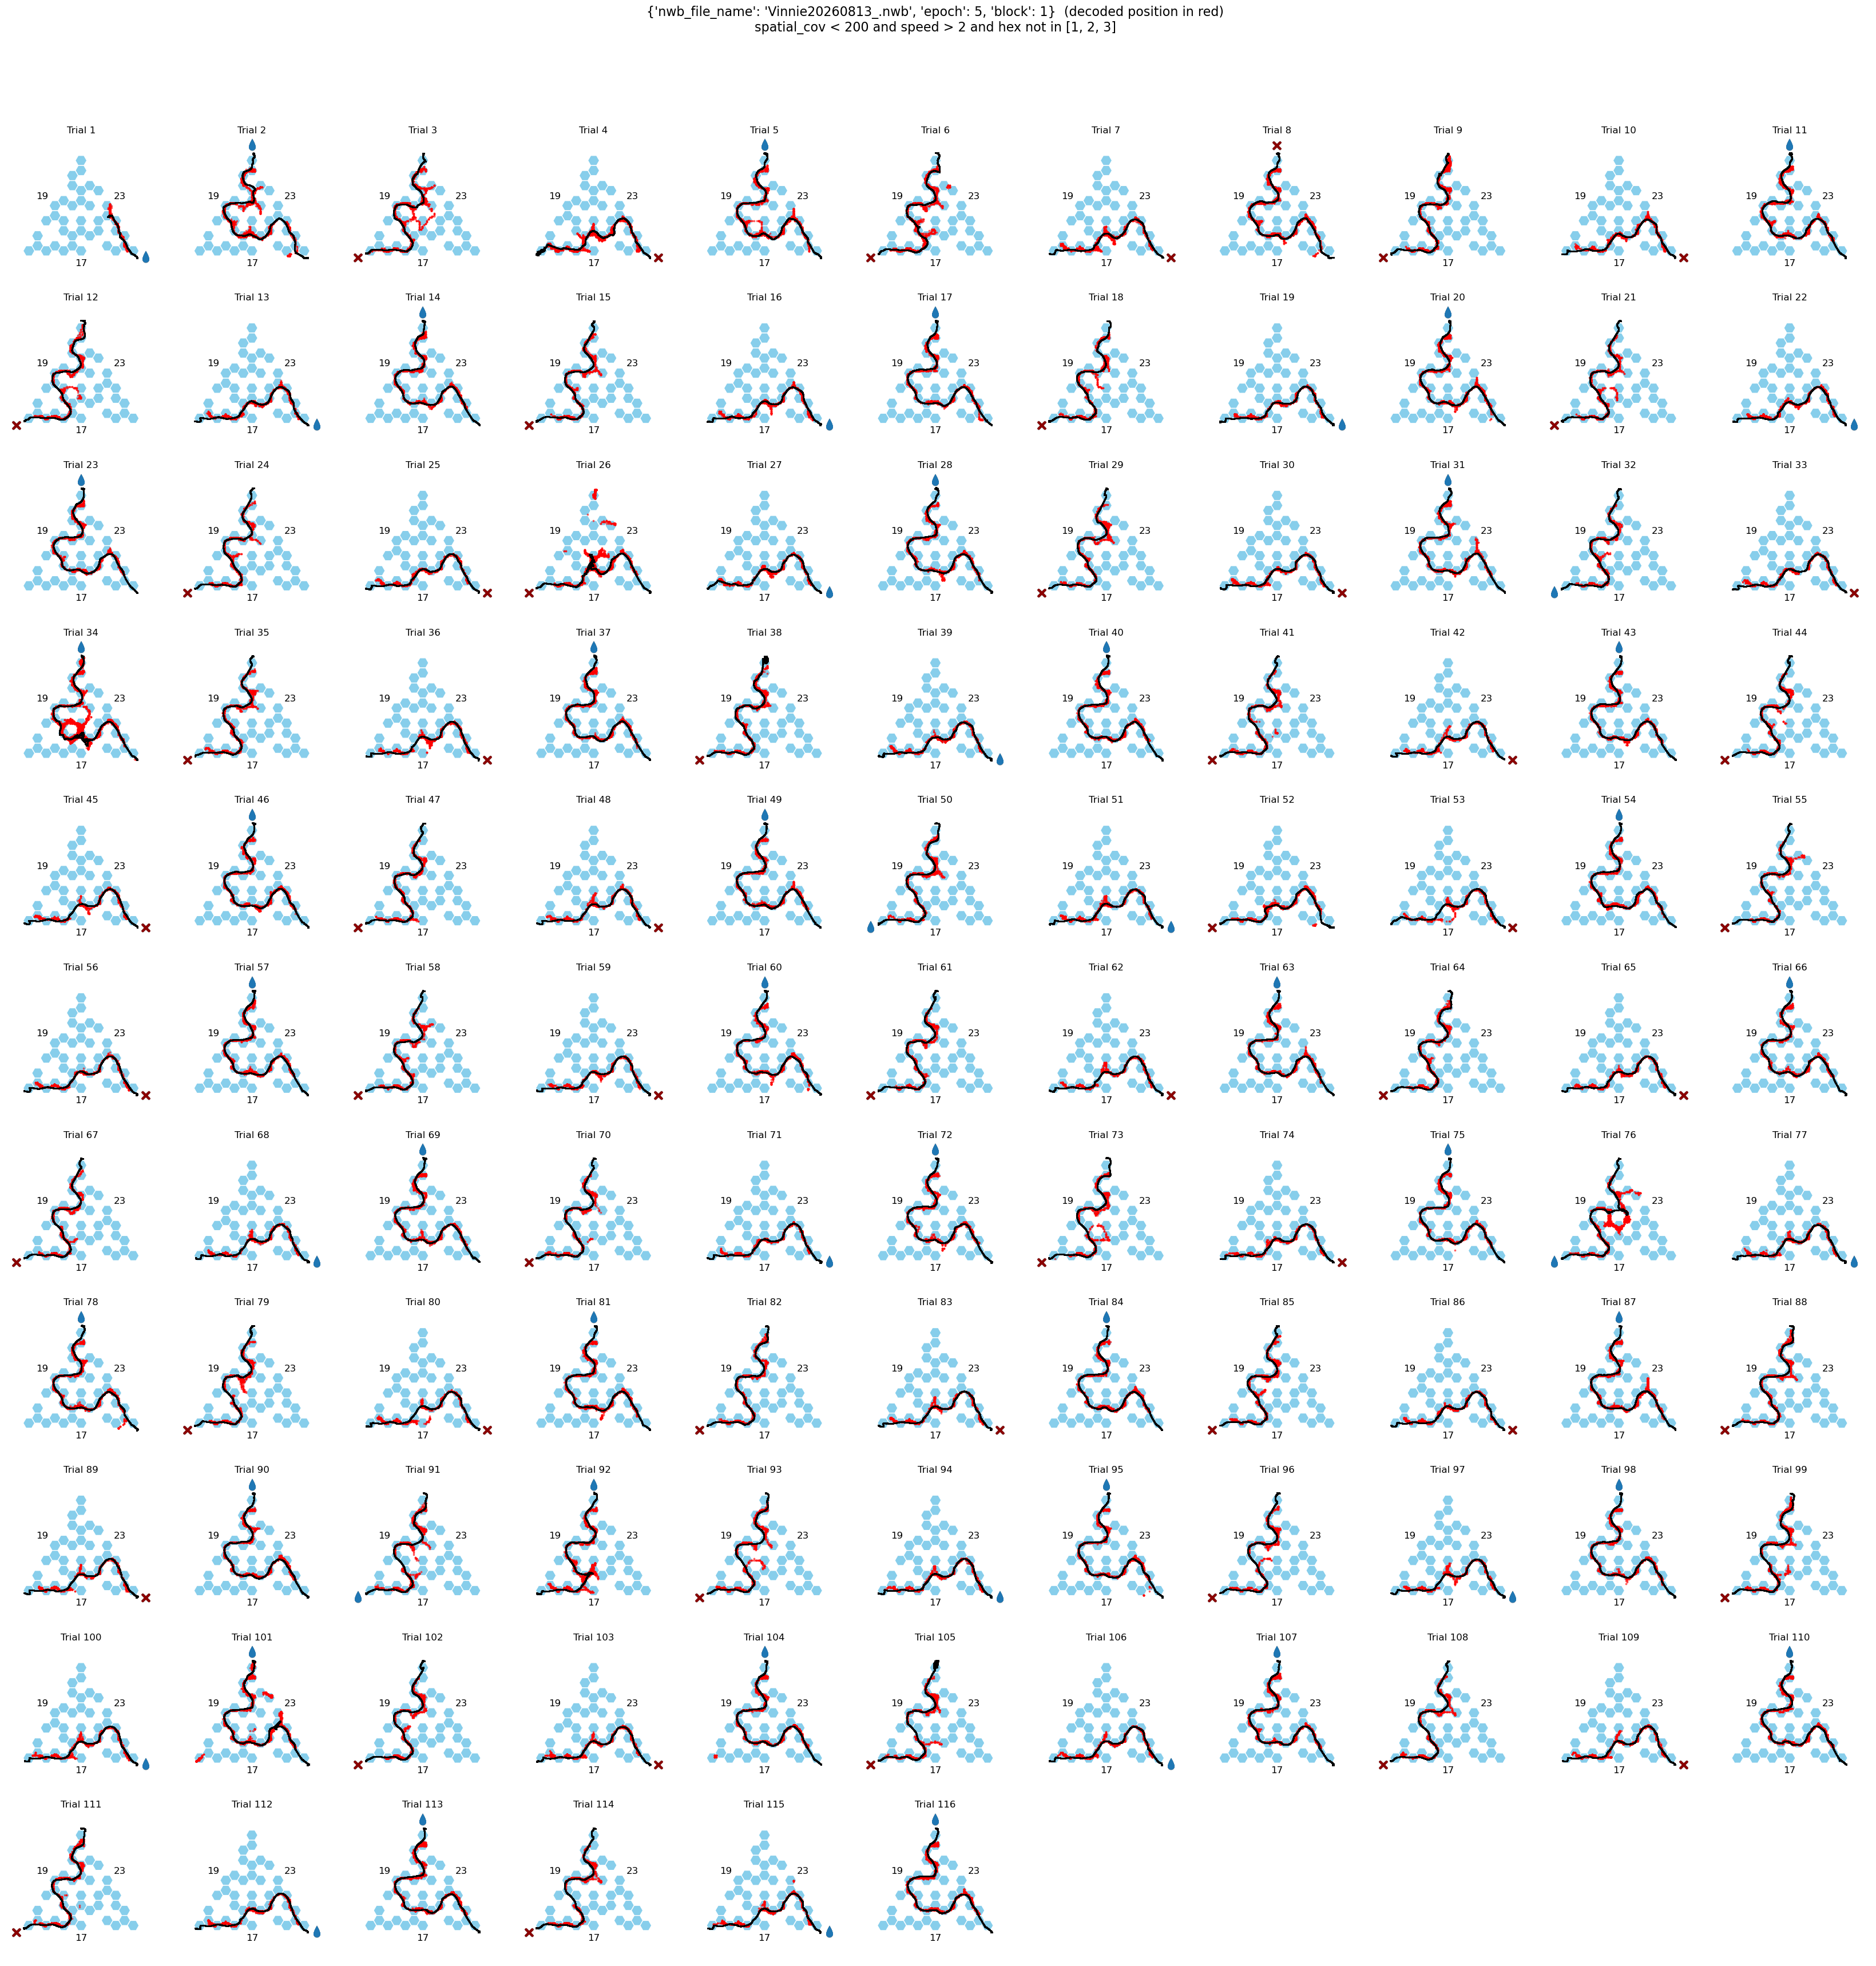

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 2}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block2_classic_d7c7a7.png


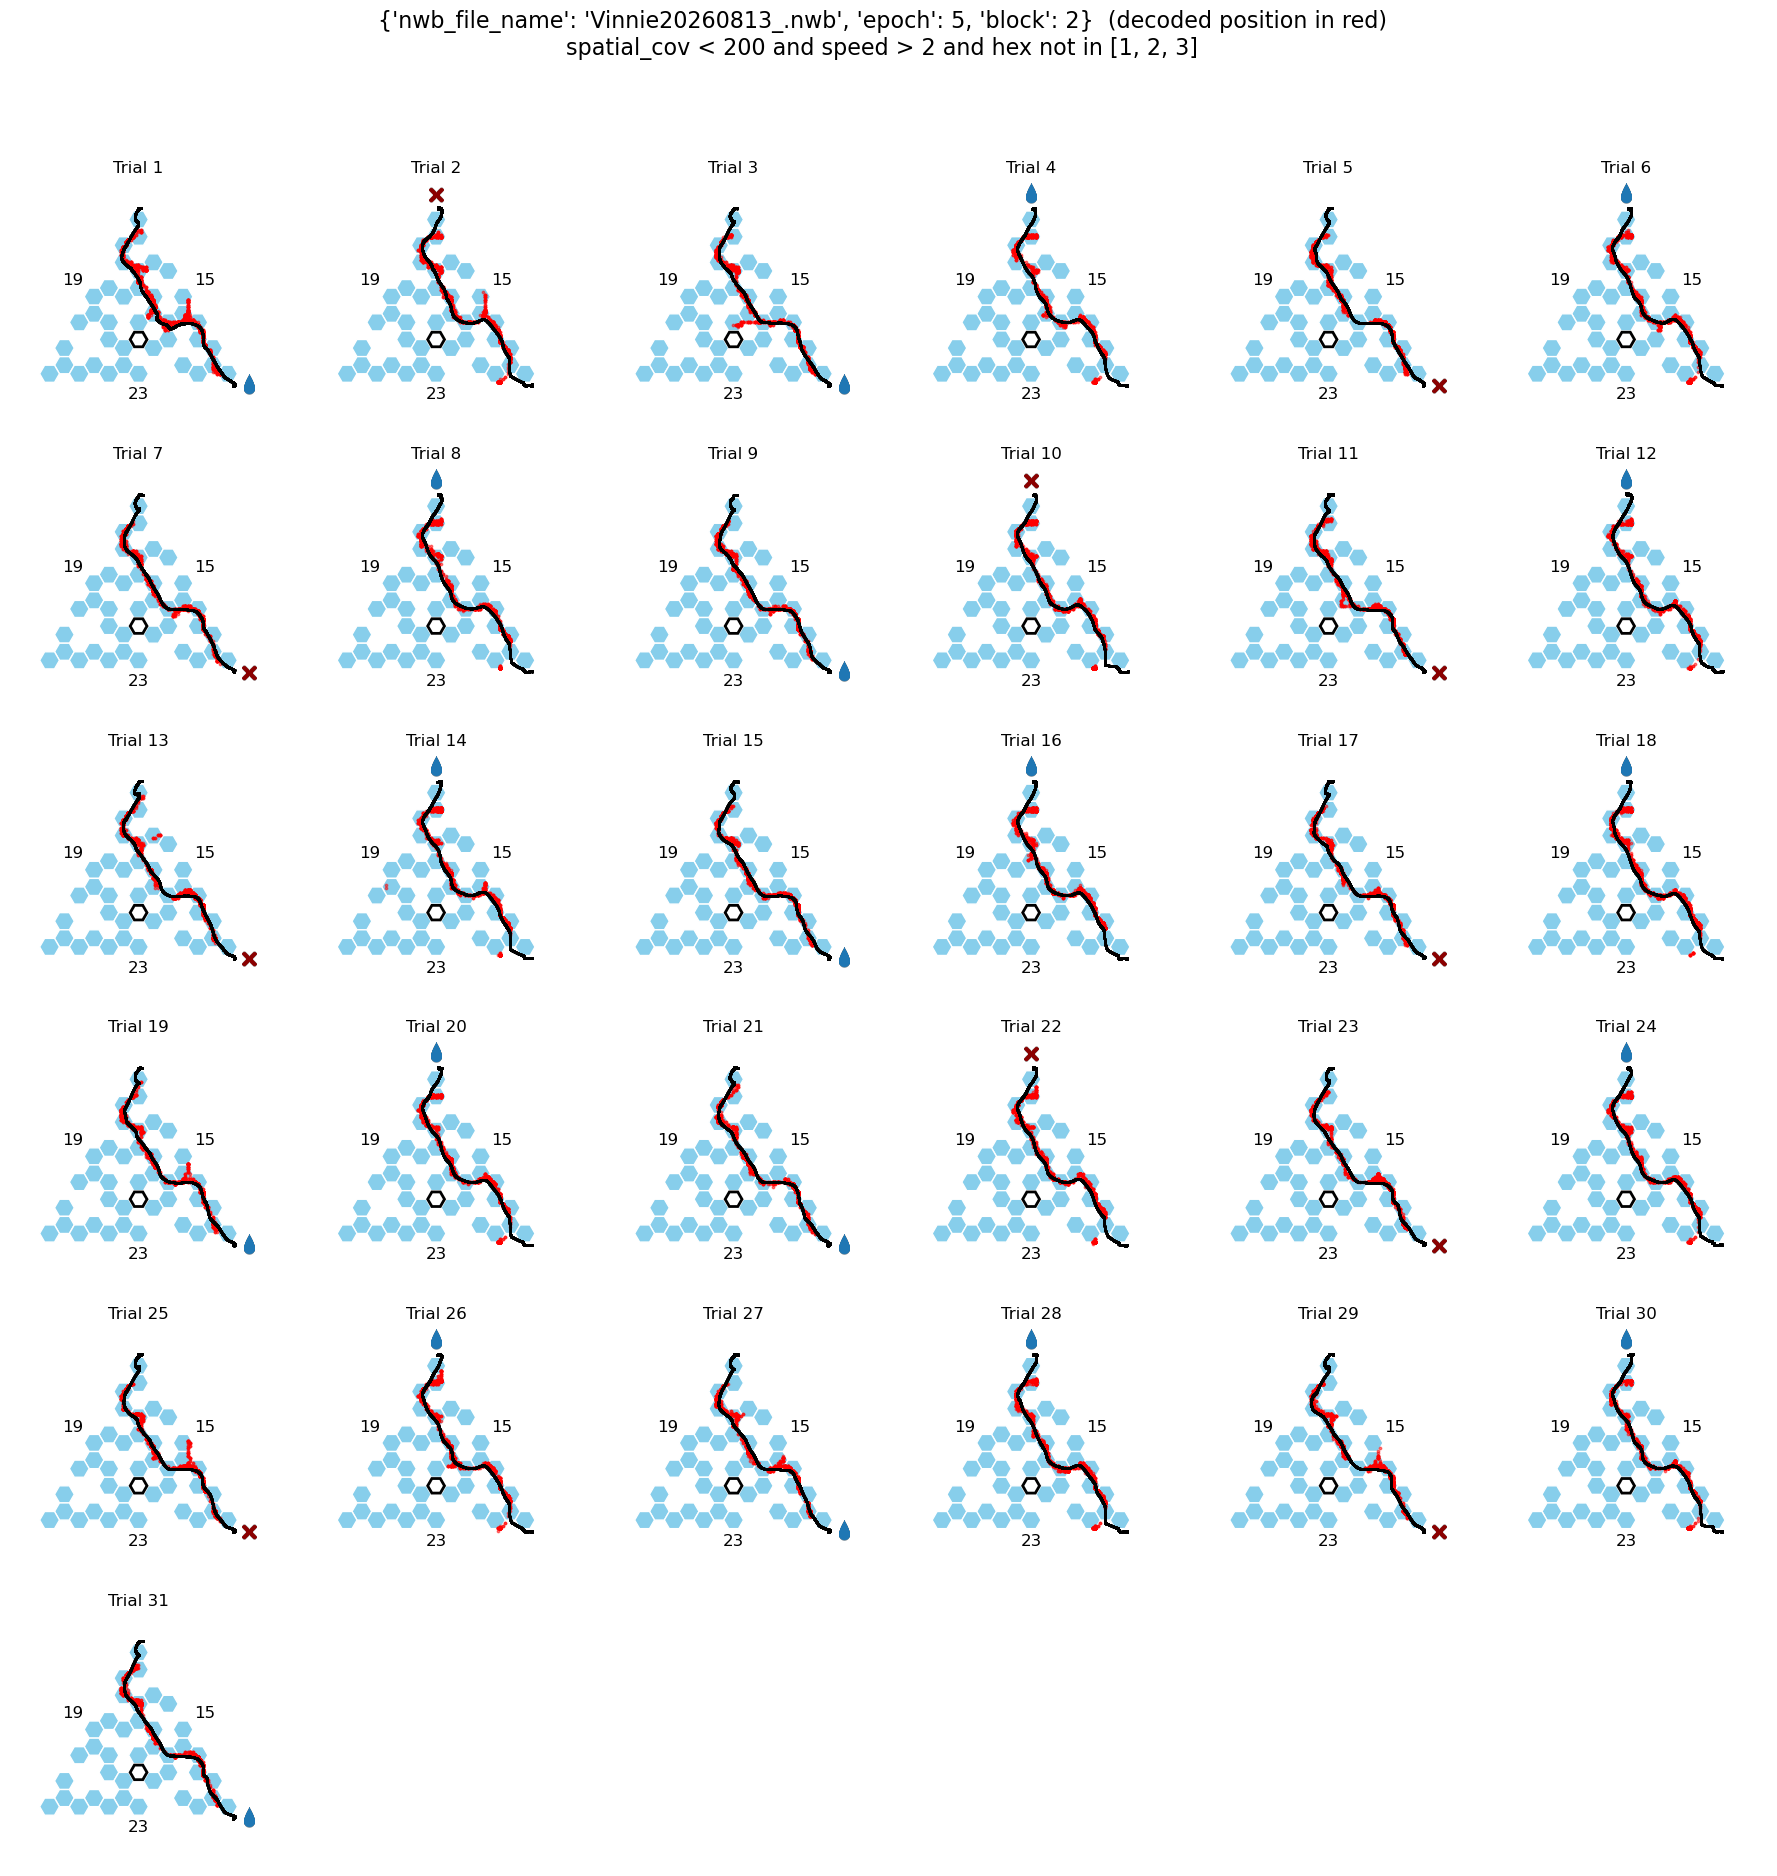

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 3}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block3_classic_d7c7a7.png


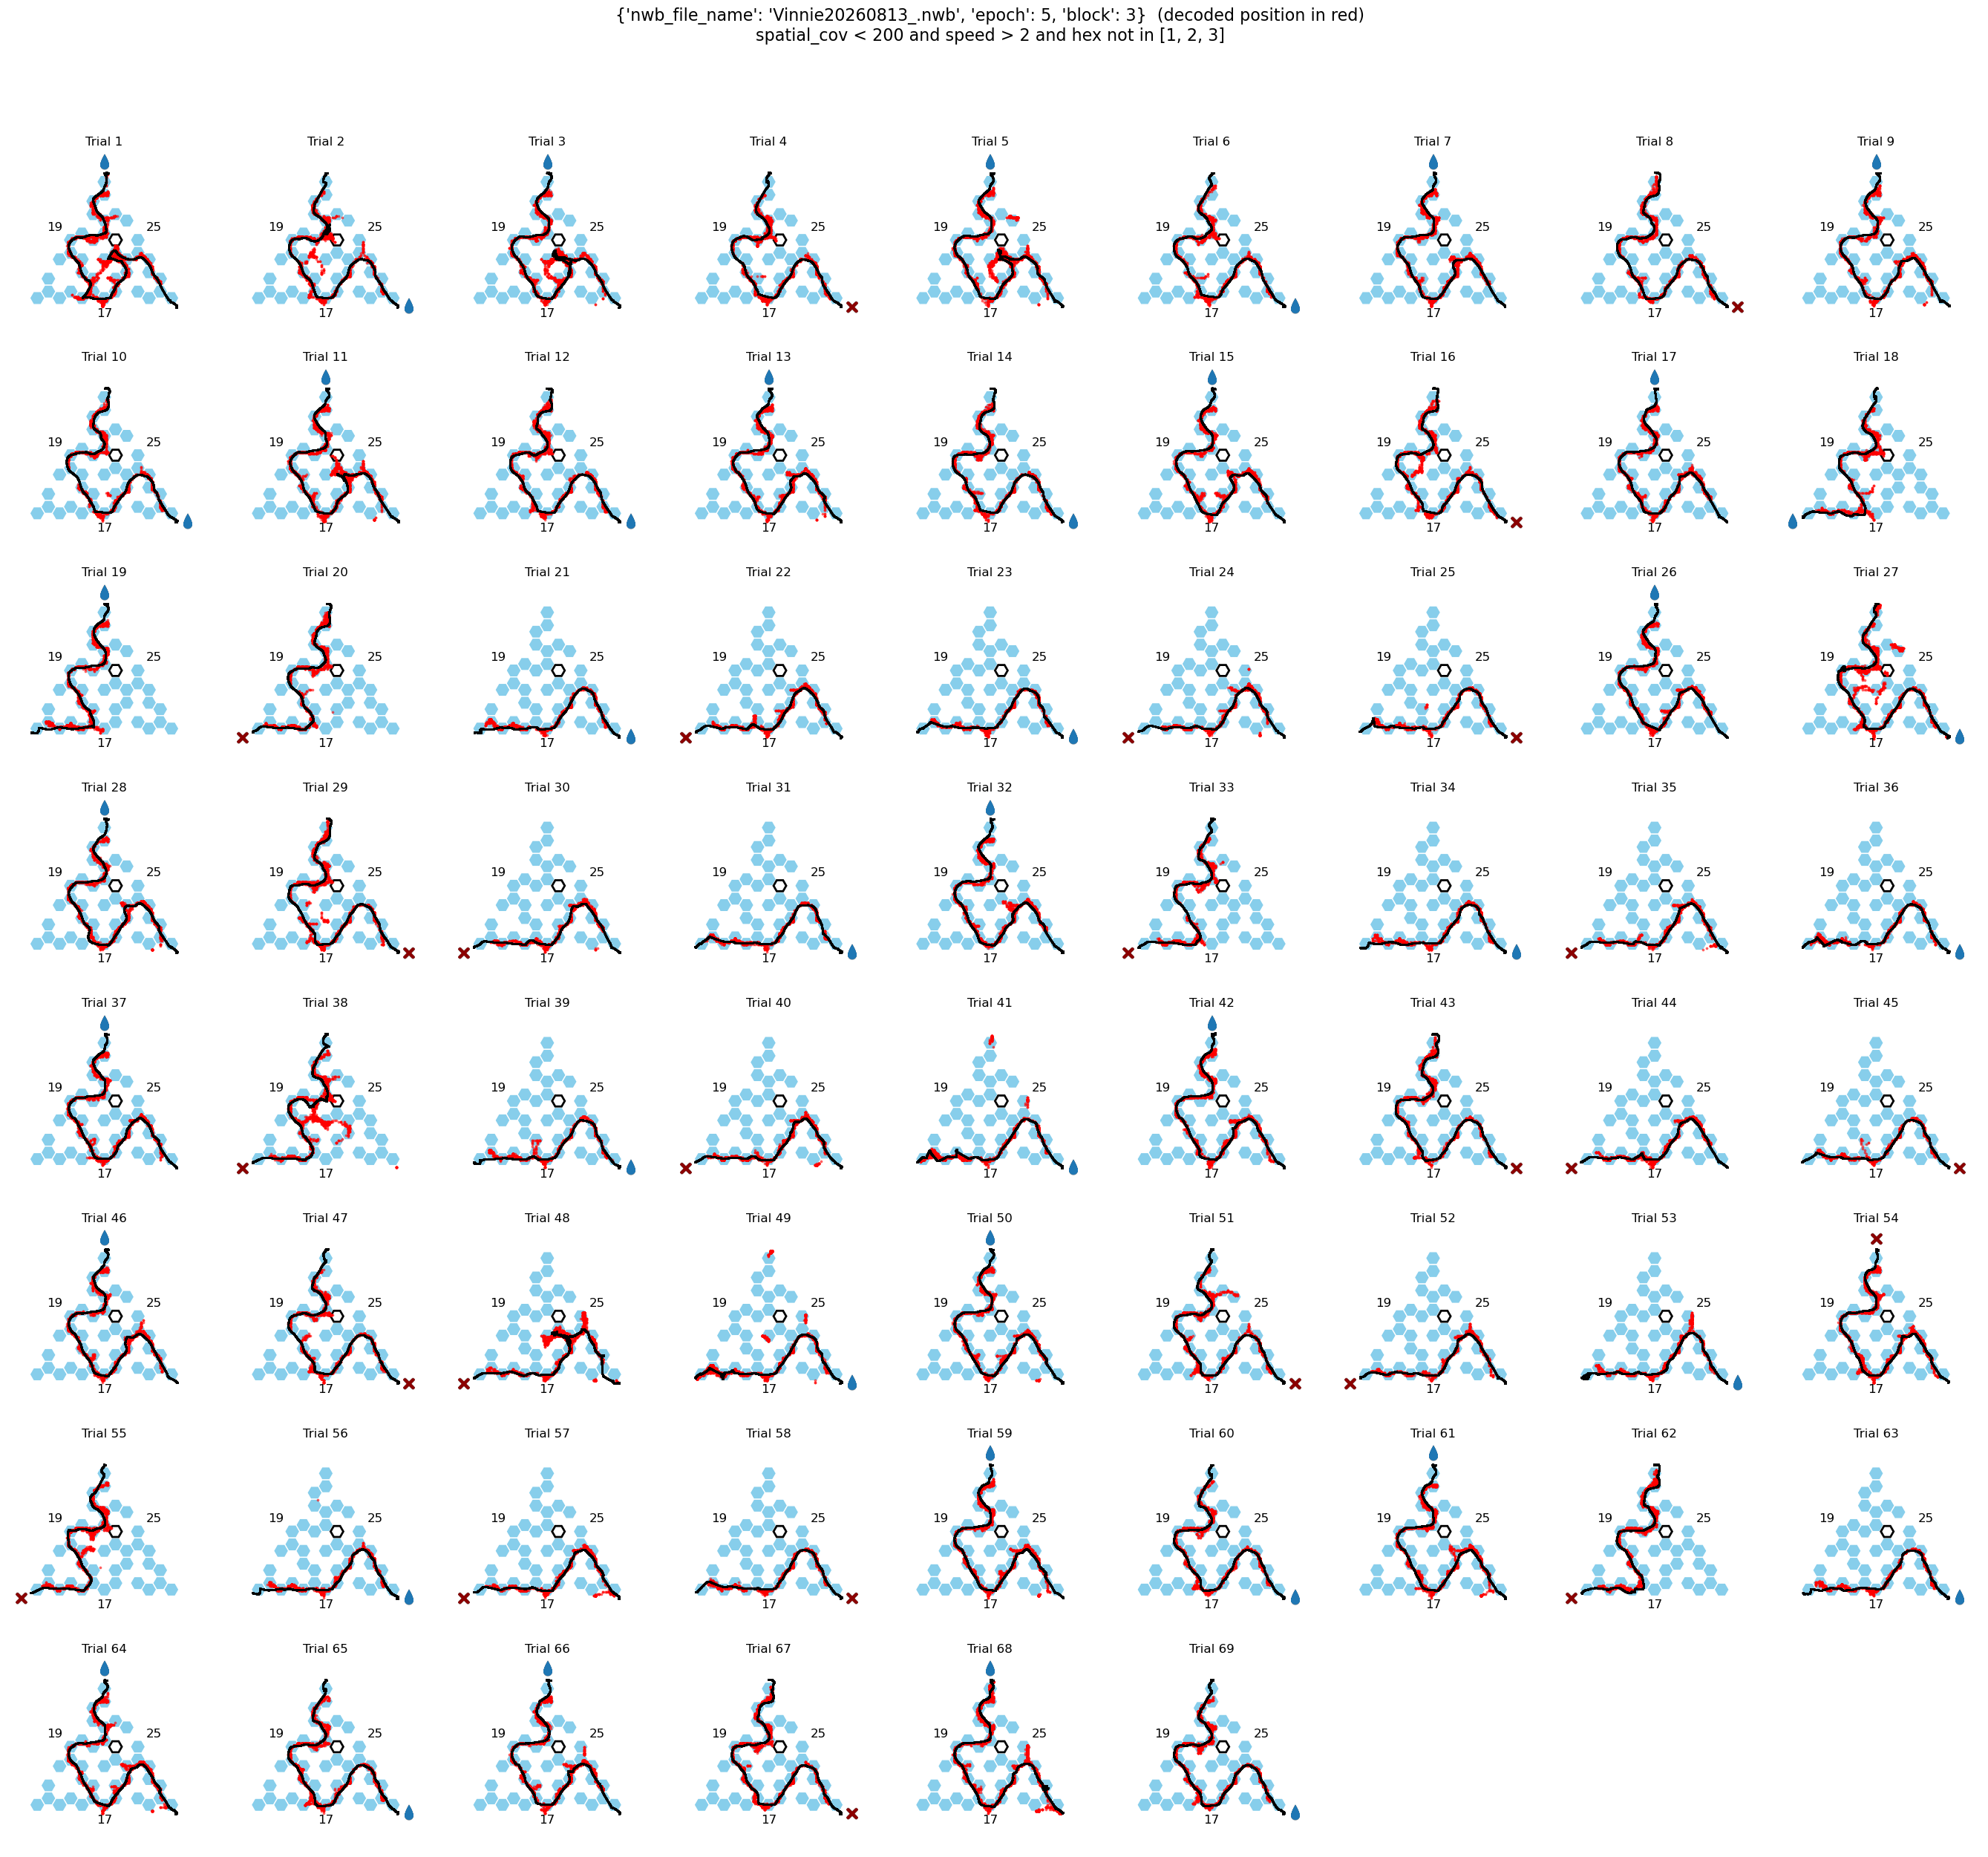

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 4}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block4_classic_d7c7a7.png


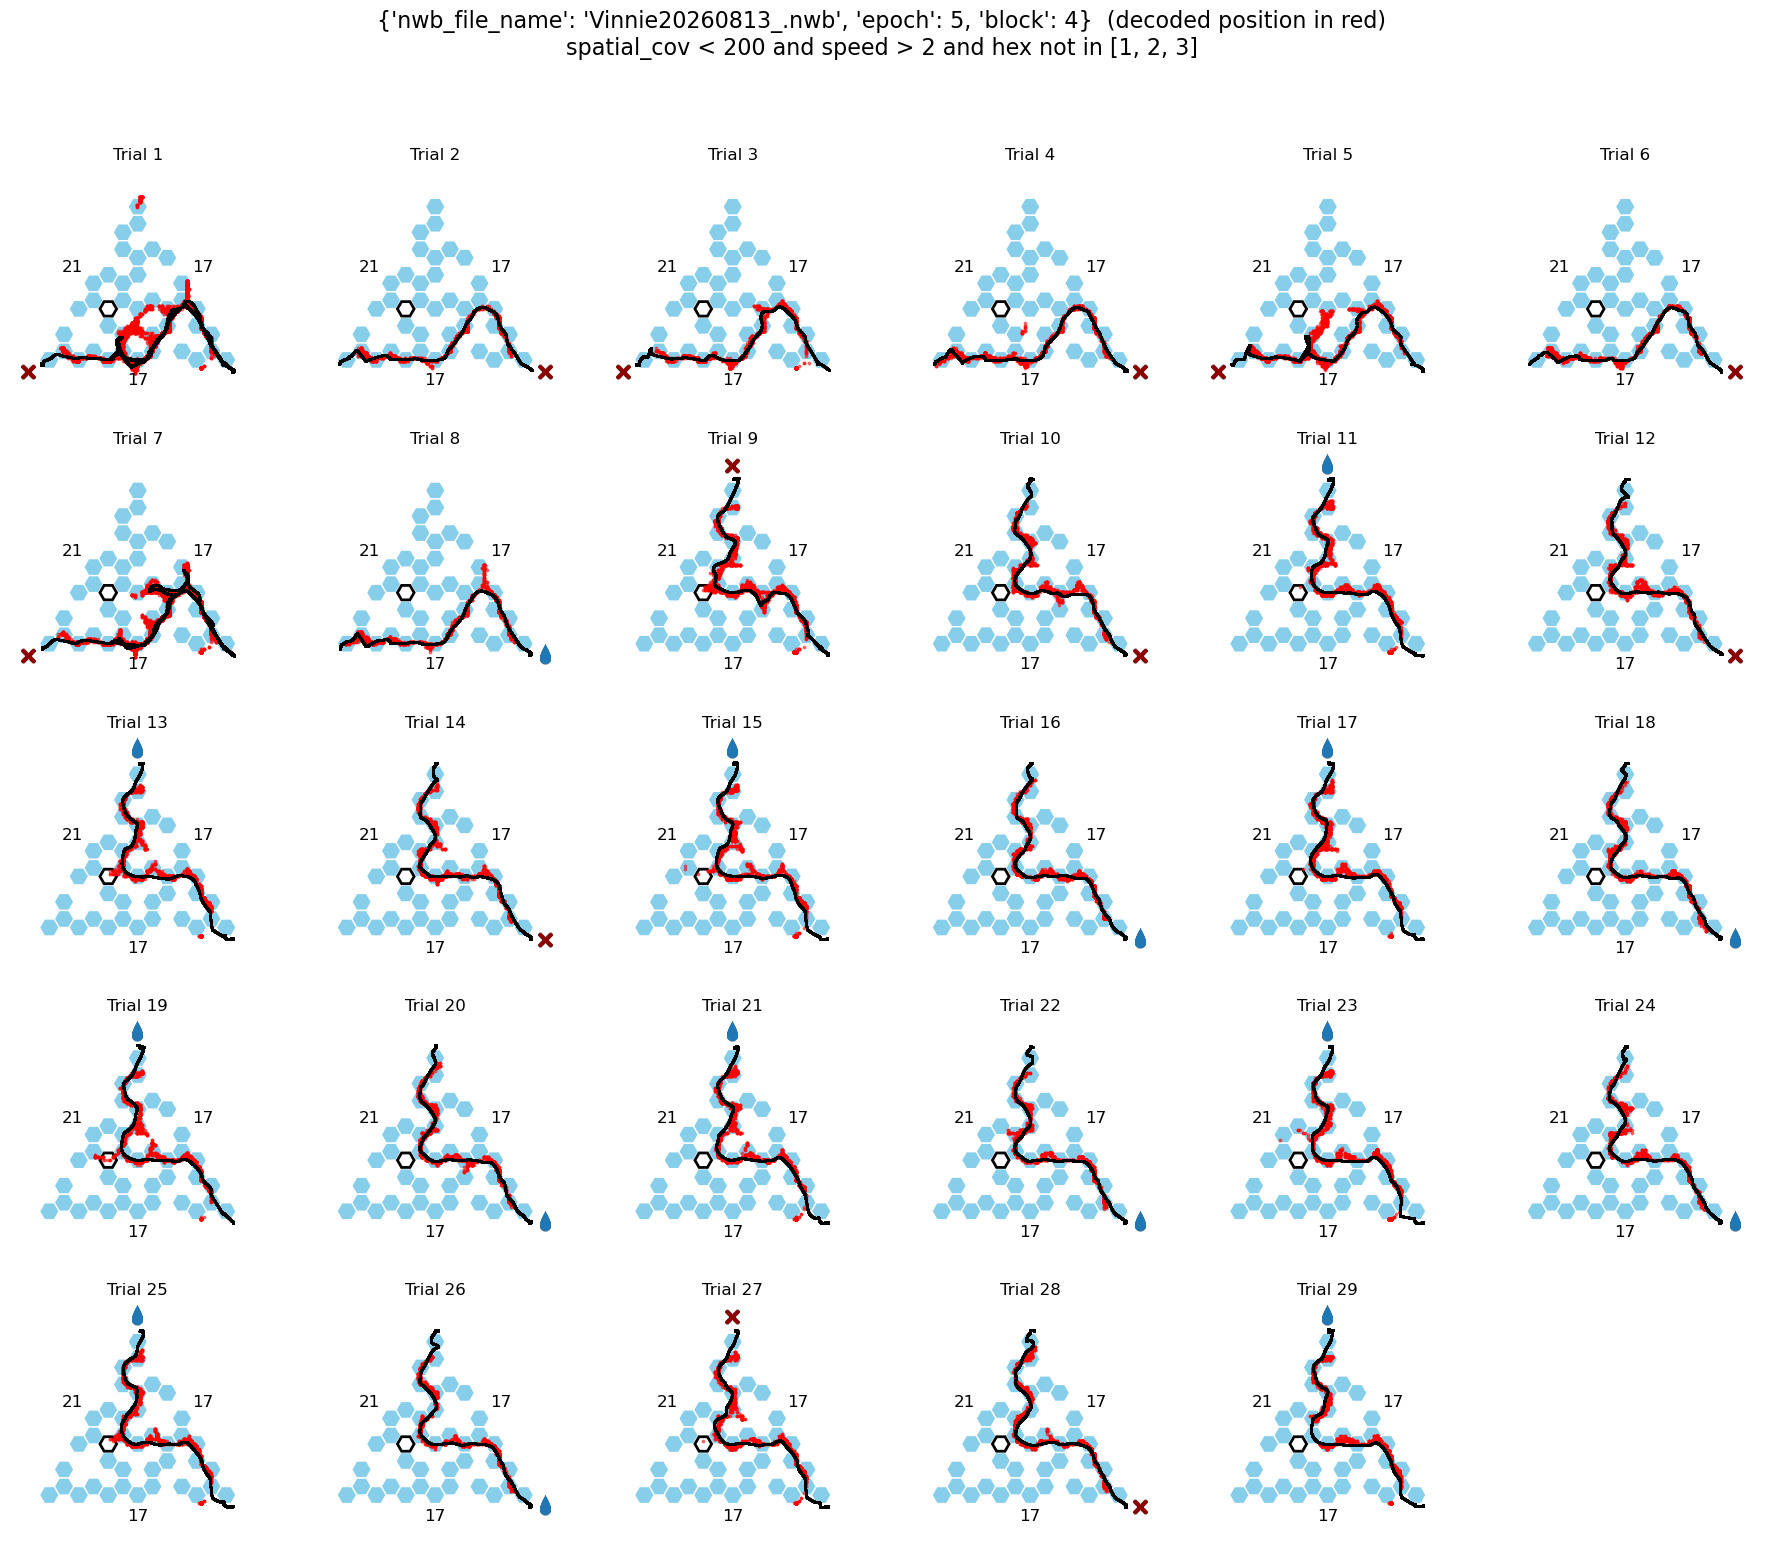

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 5}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block5_classic_d7c7a7.png


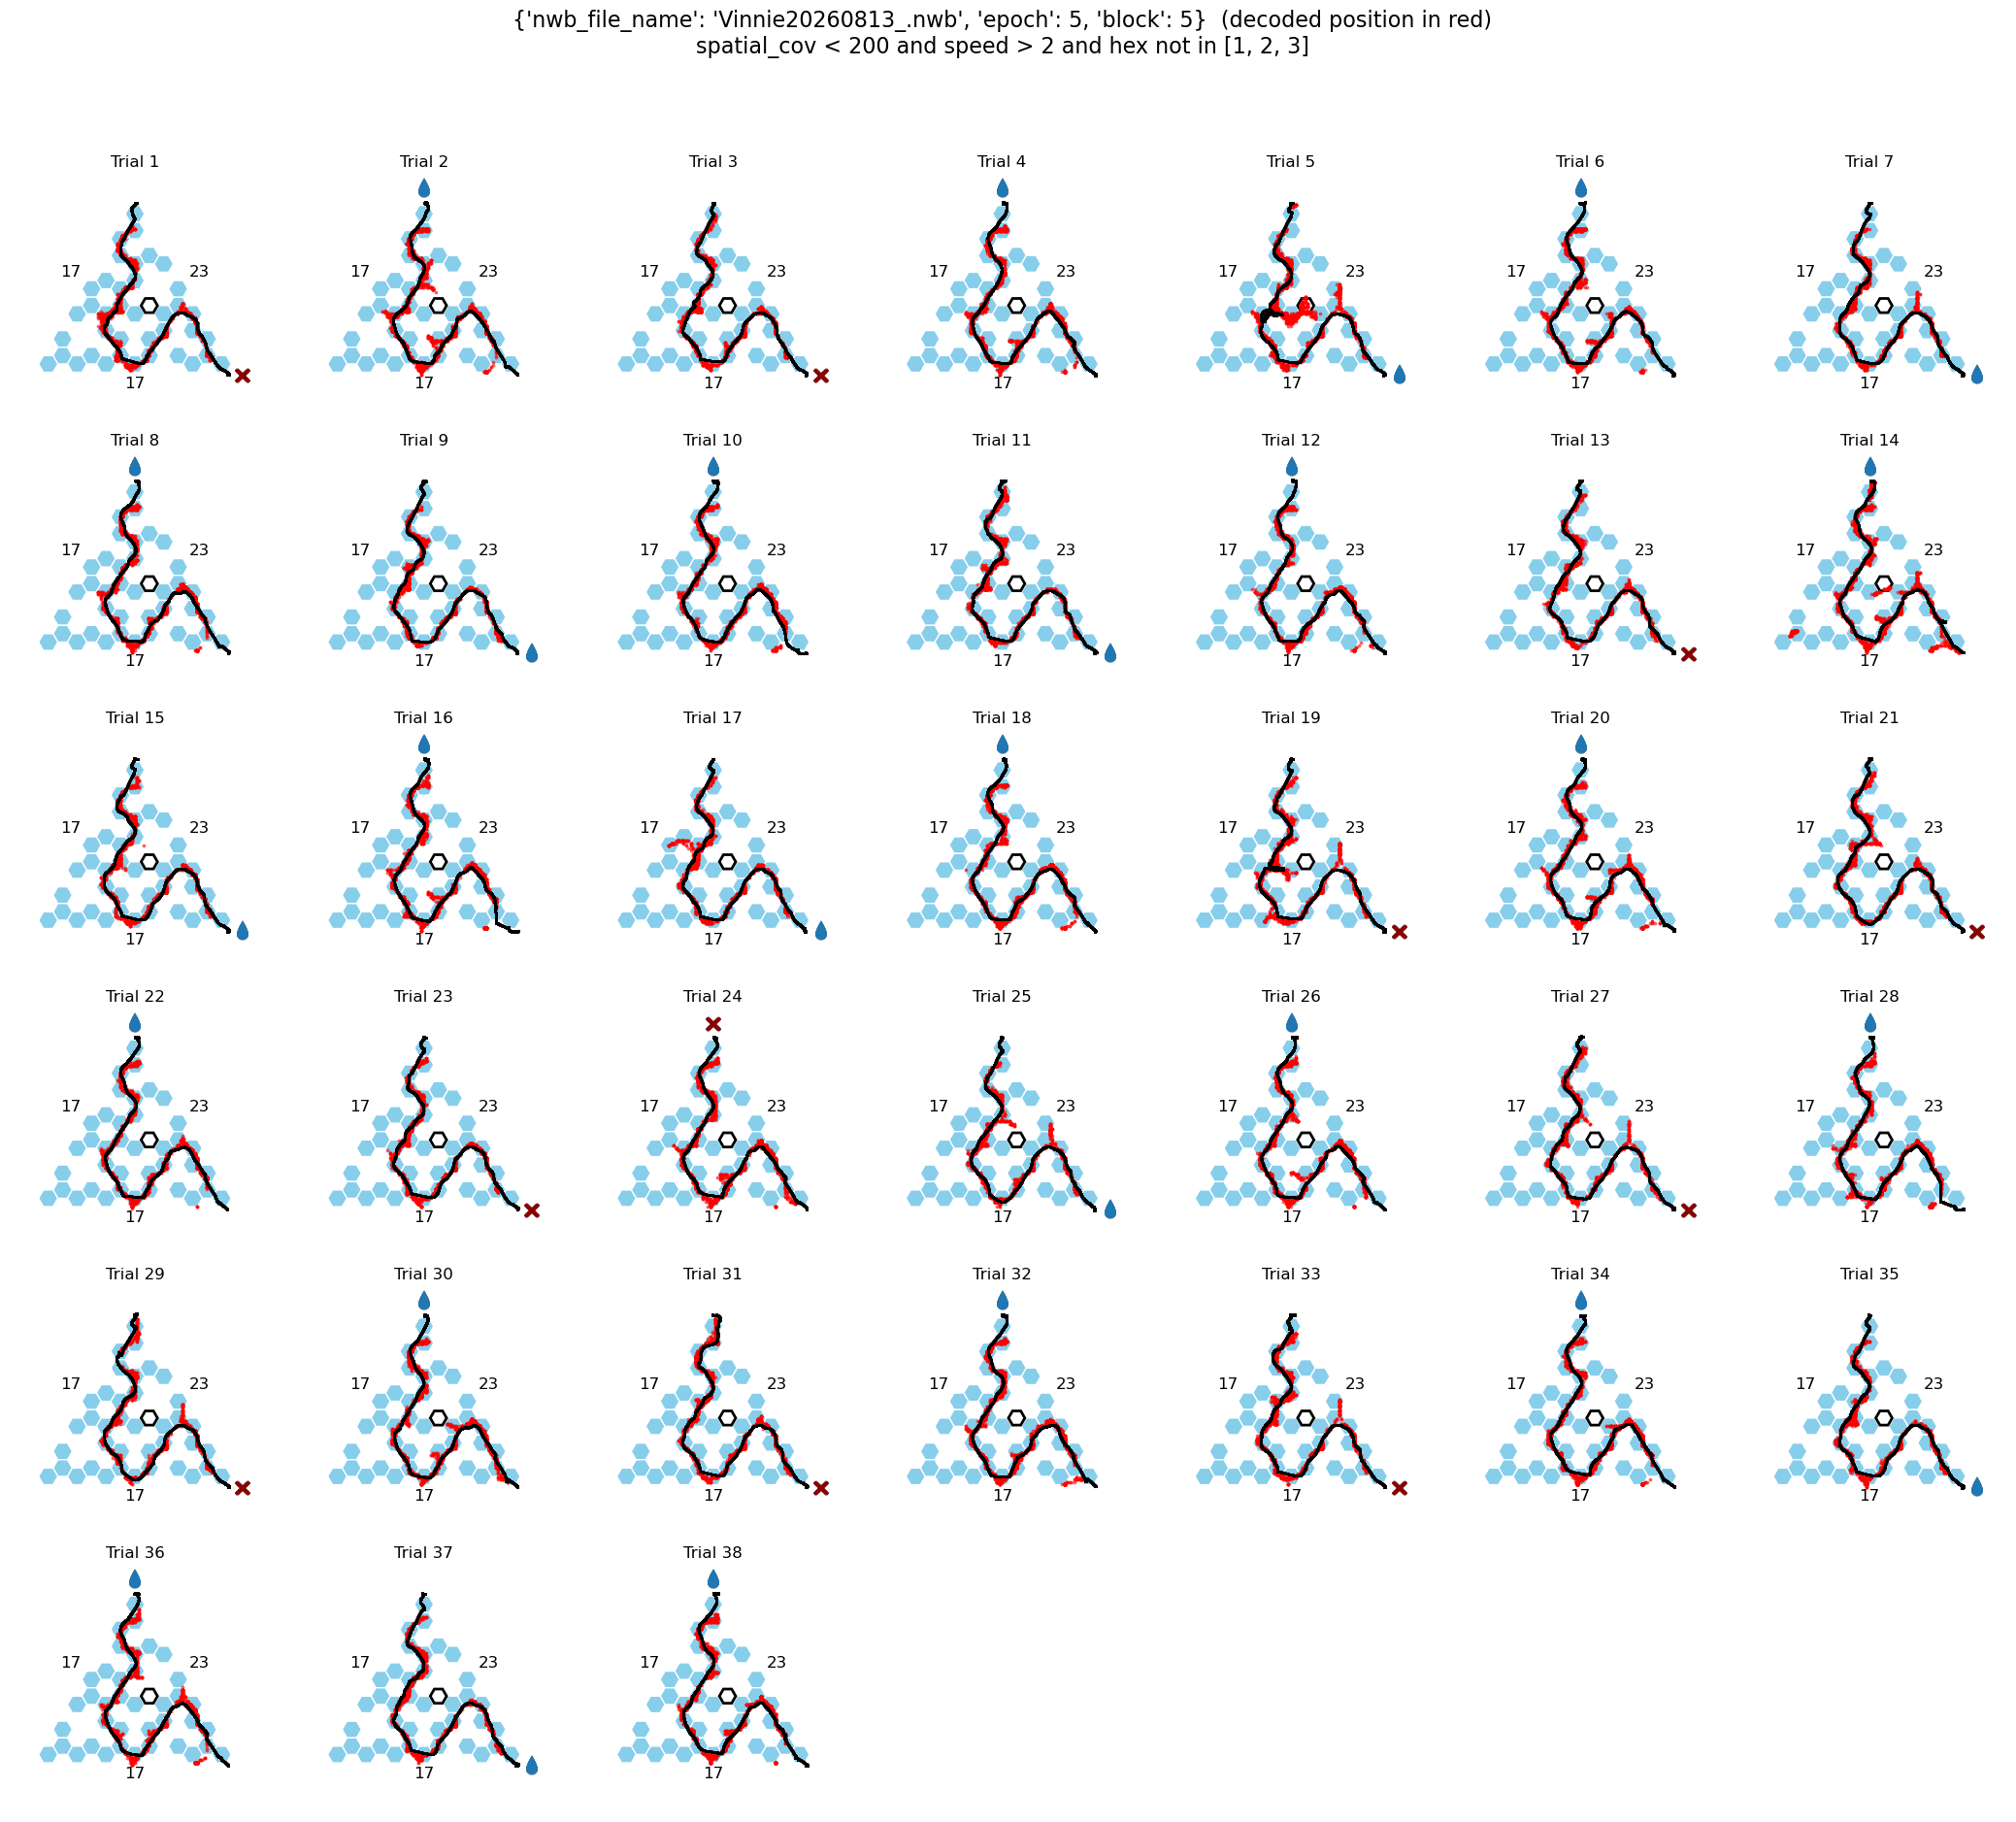

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 6}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block6_classic_d7c7a7.png


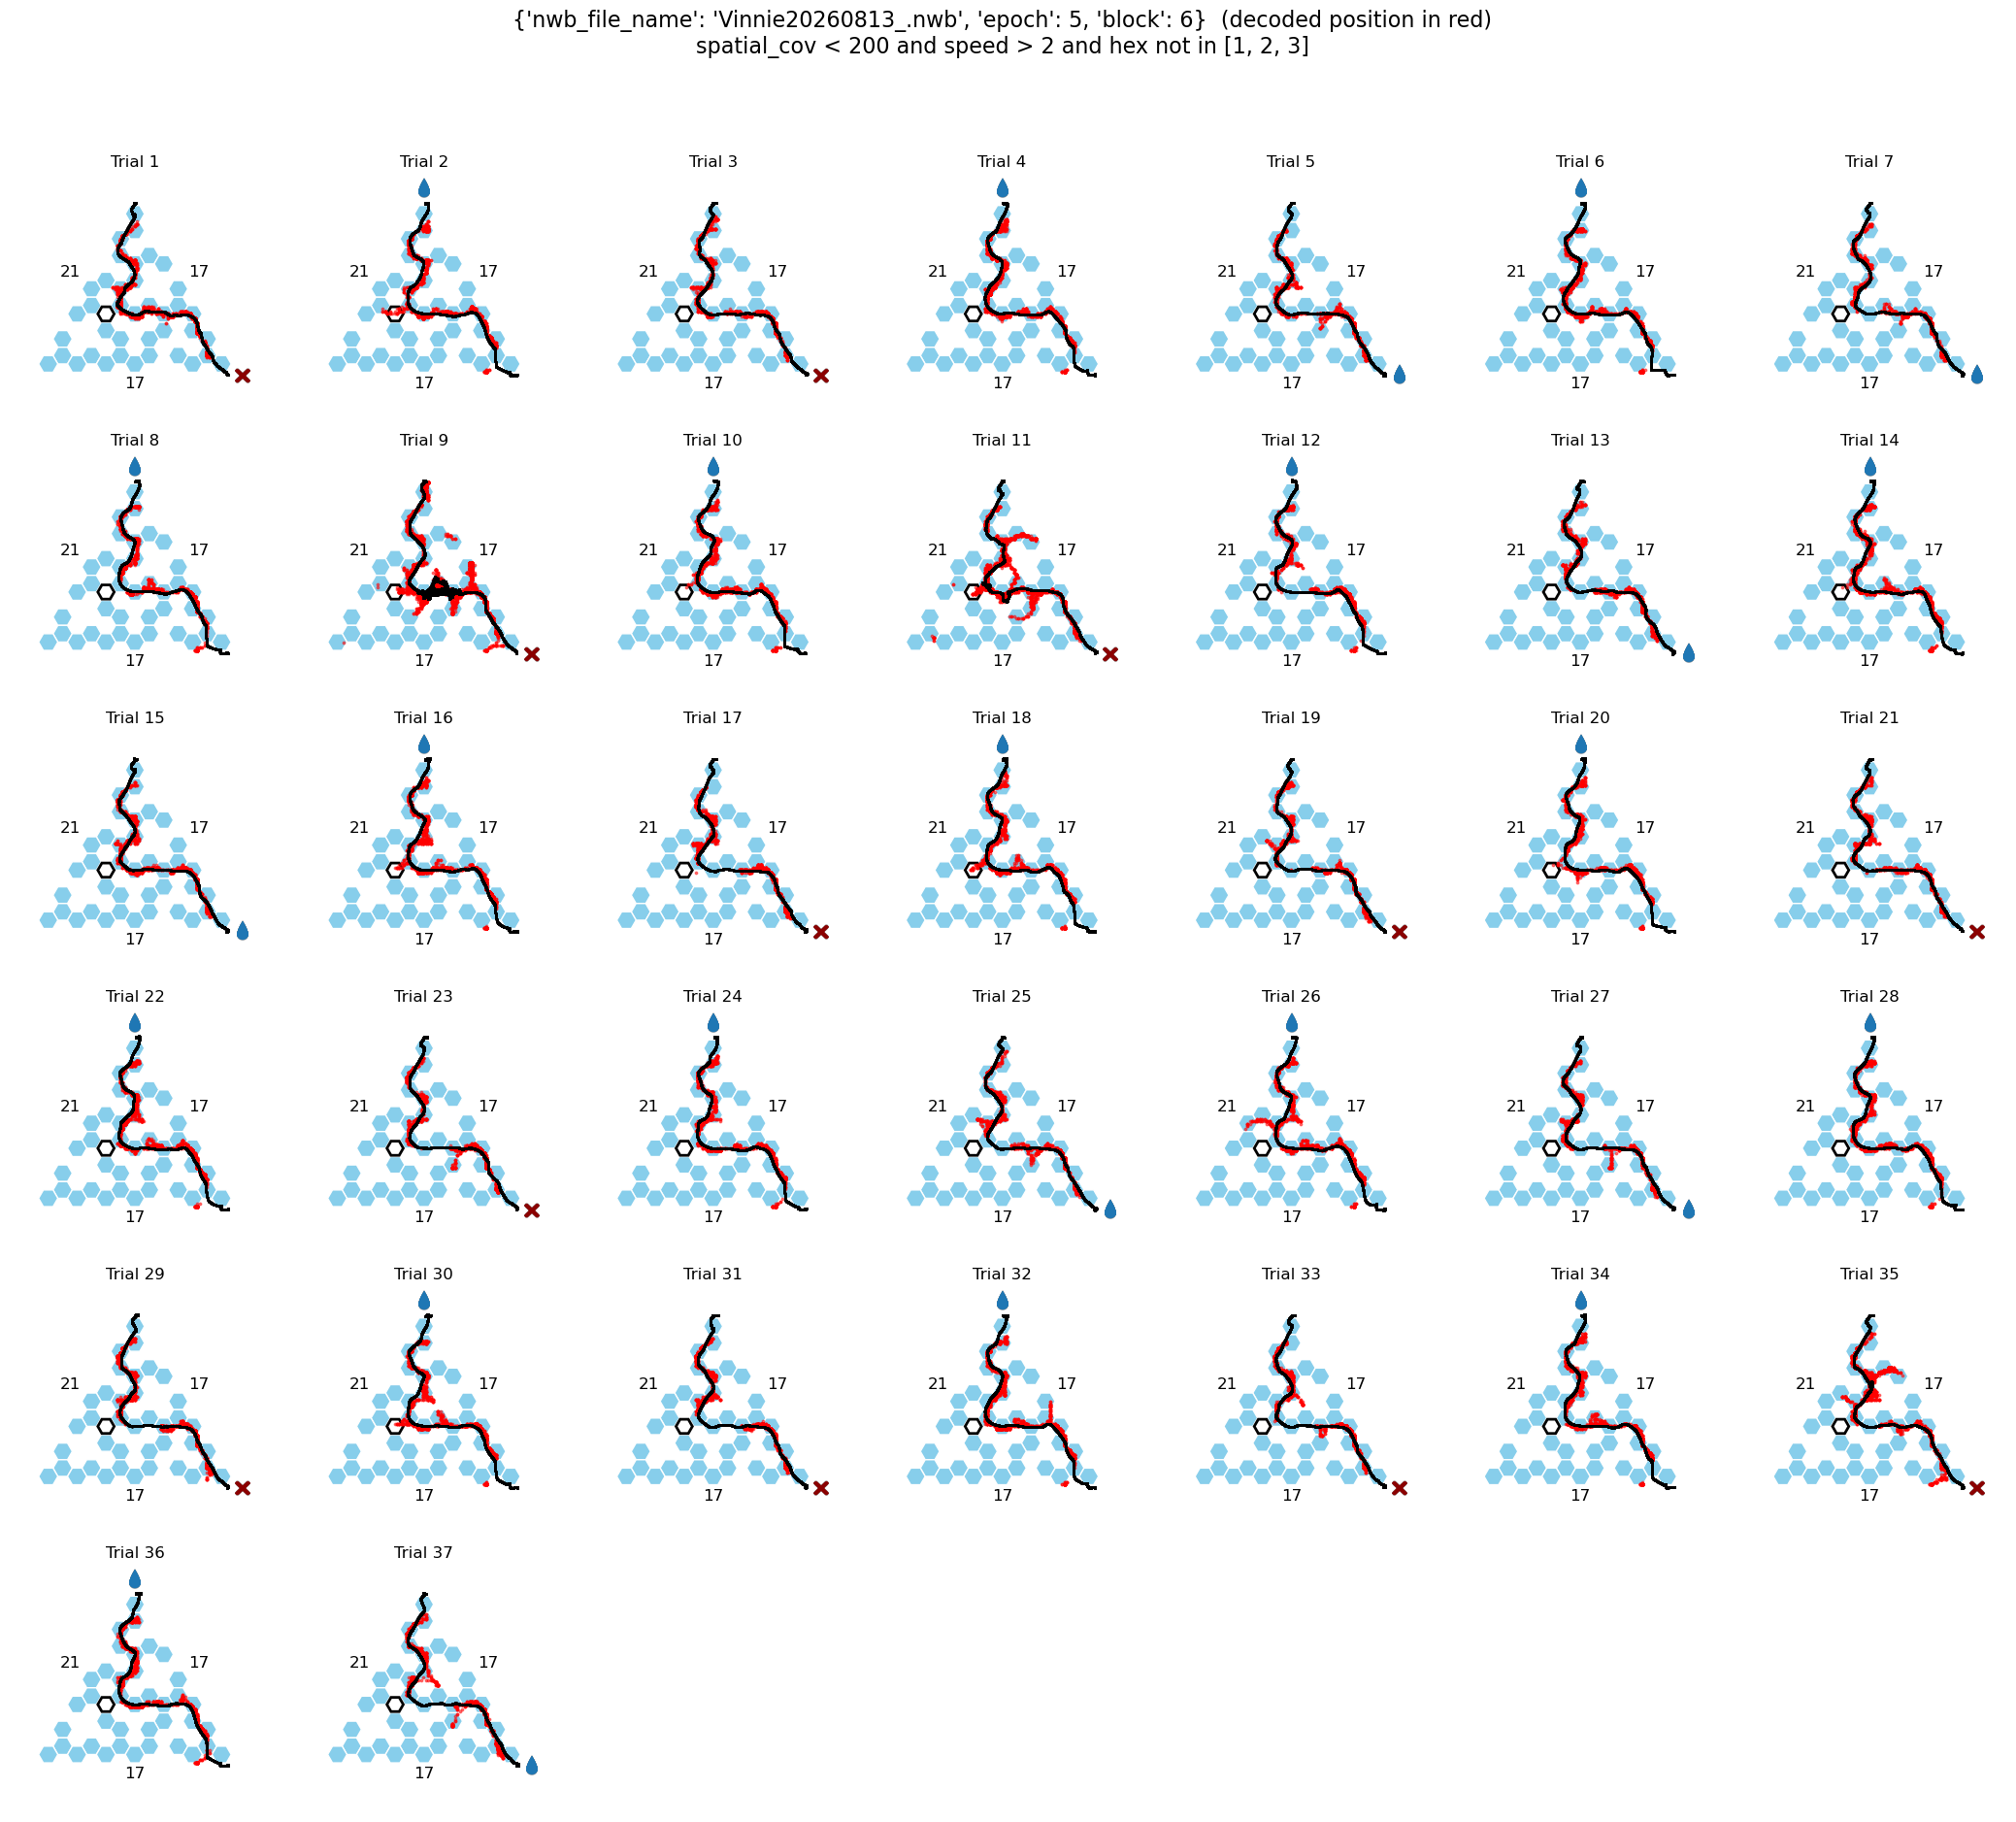

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 7}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block7_classic_d7c7a7.png


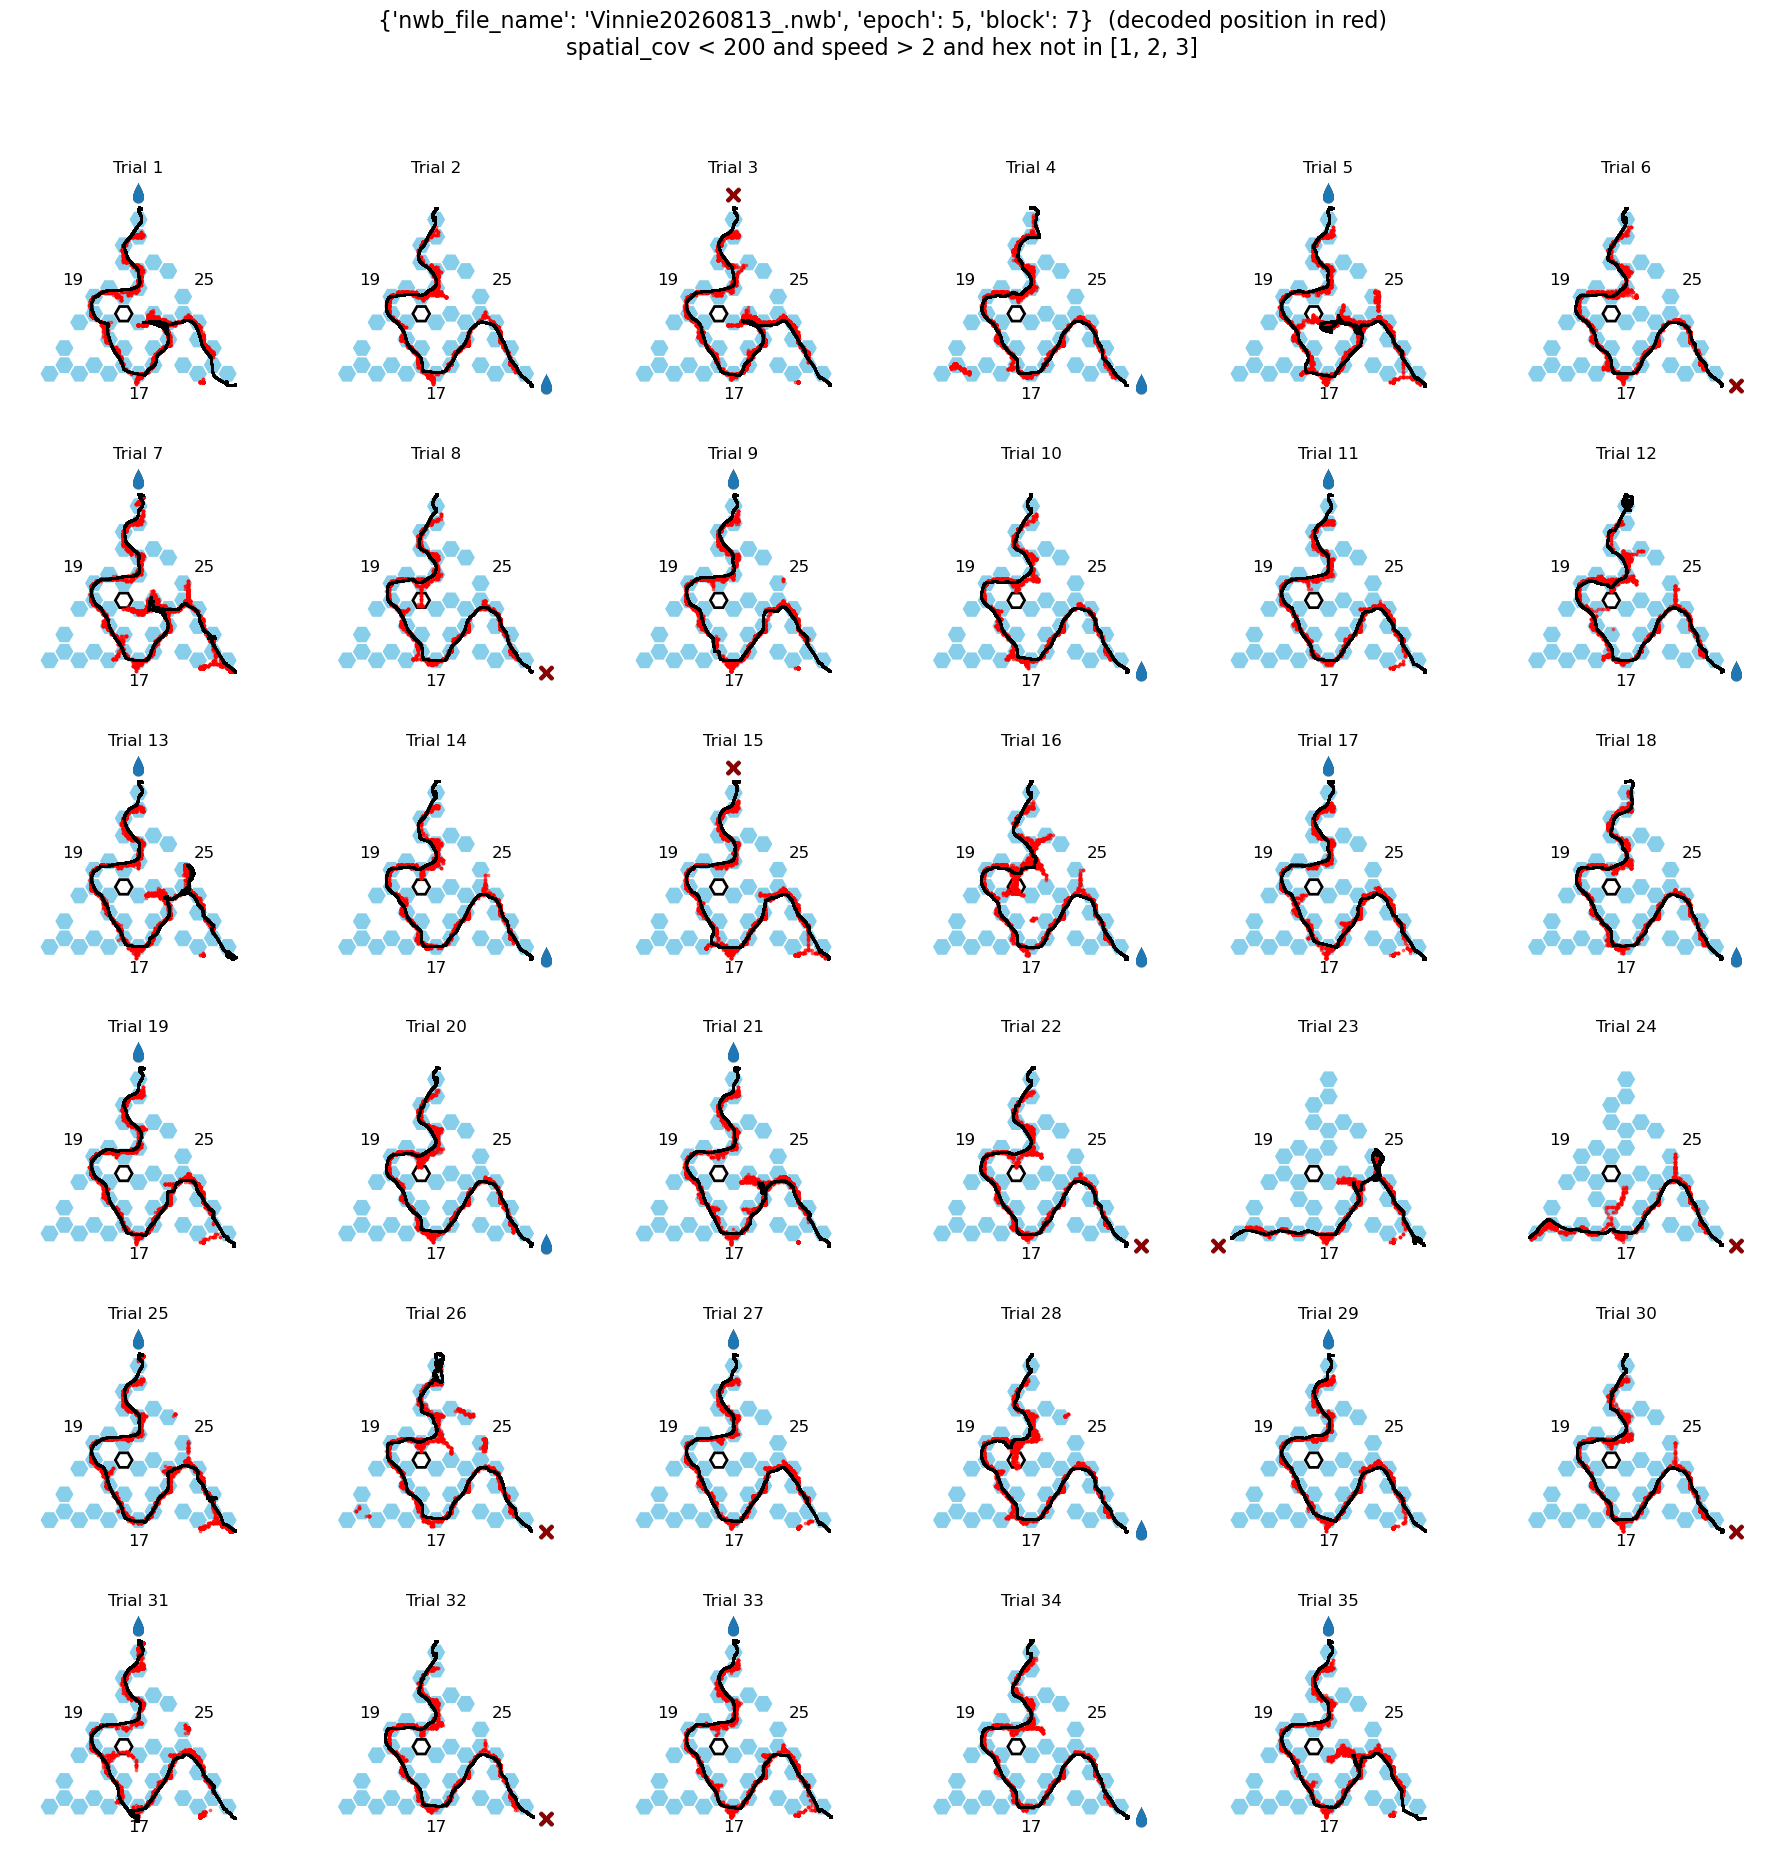

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 8}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block8_classic_d7c7a7.png


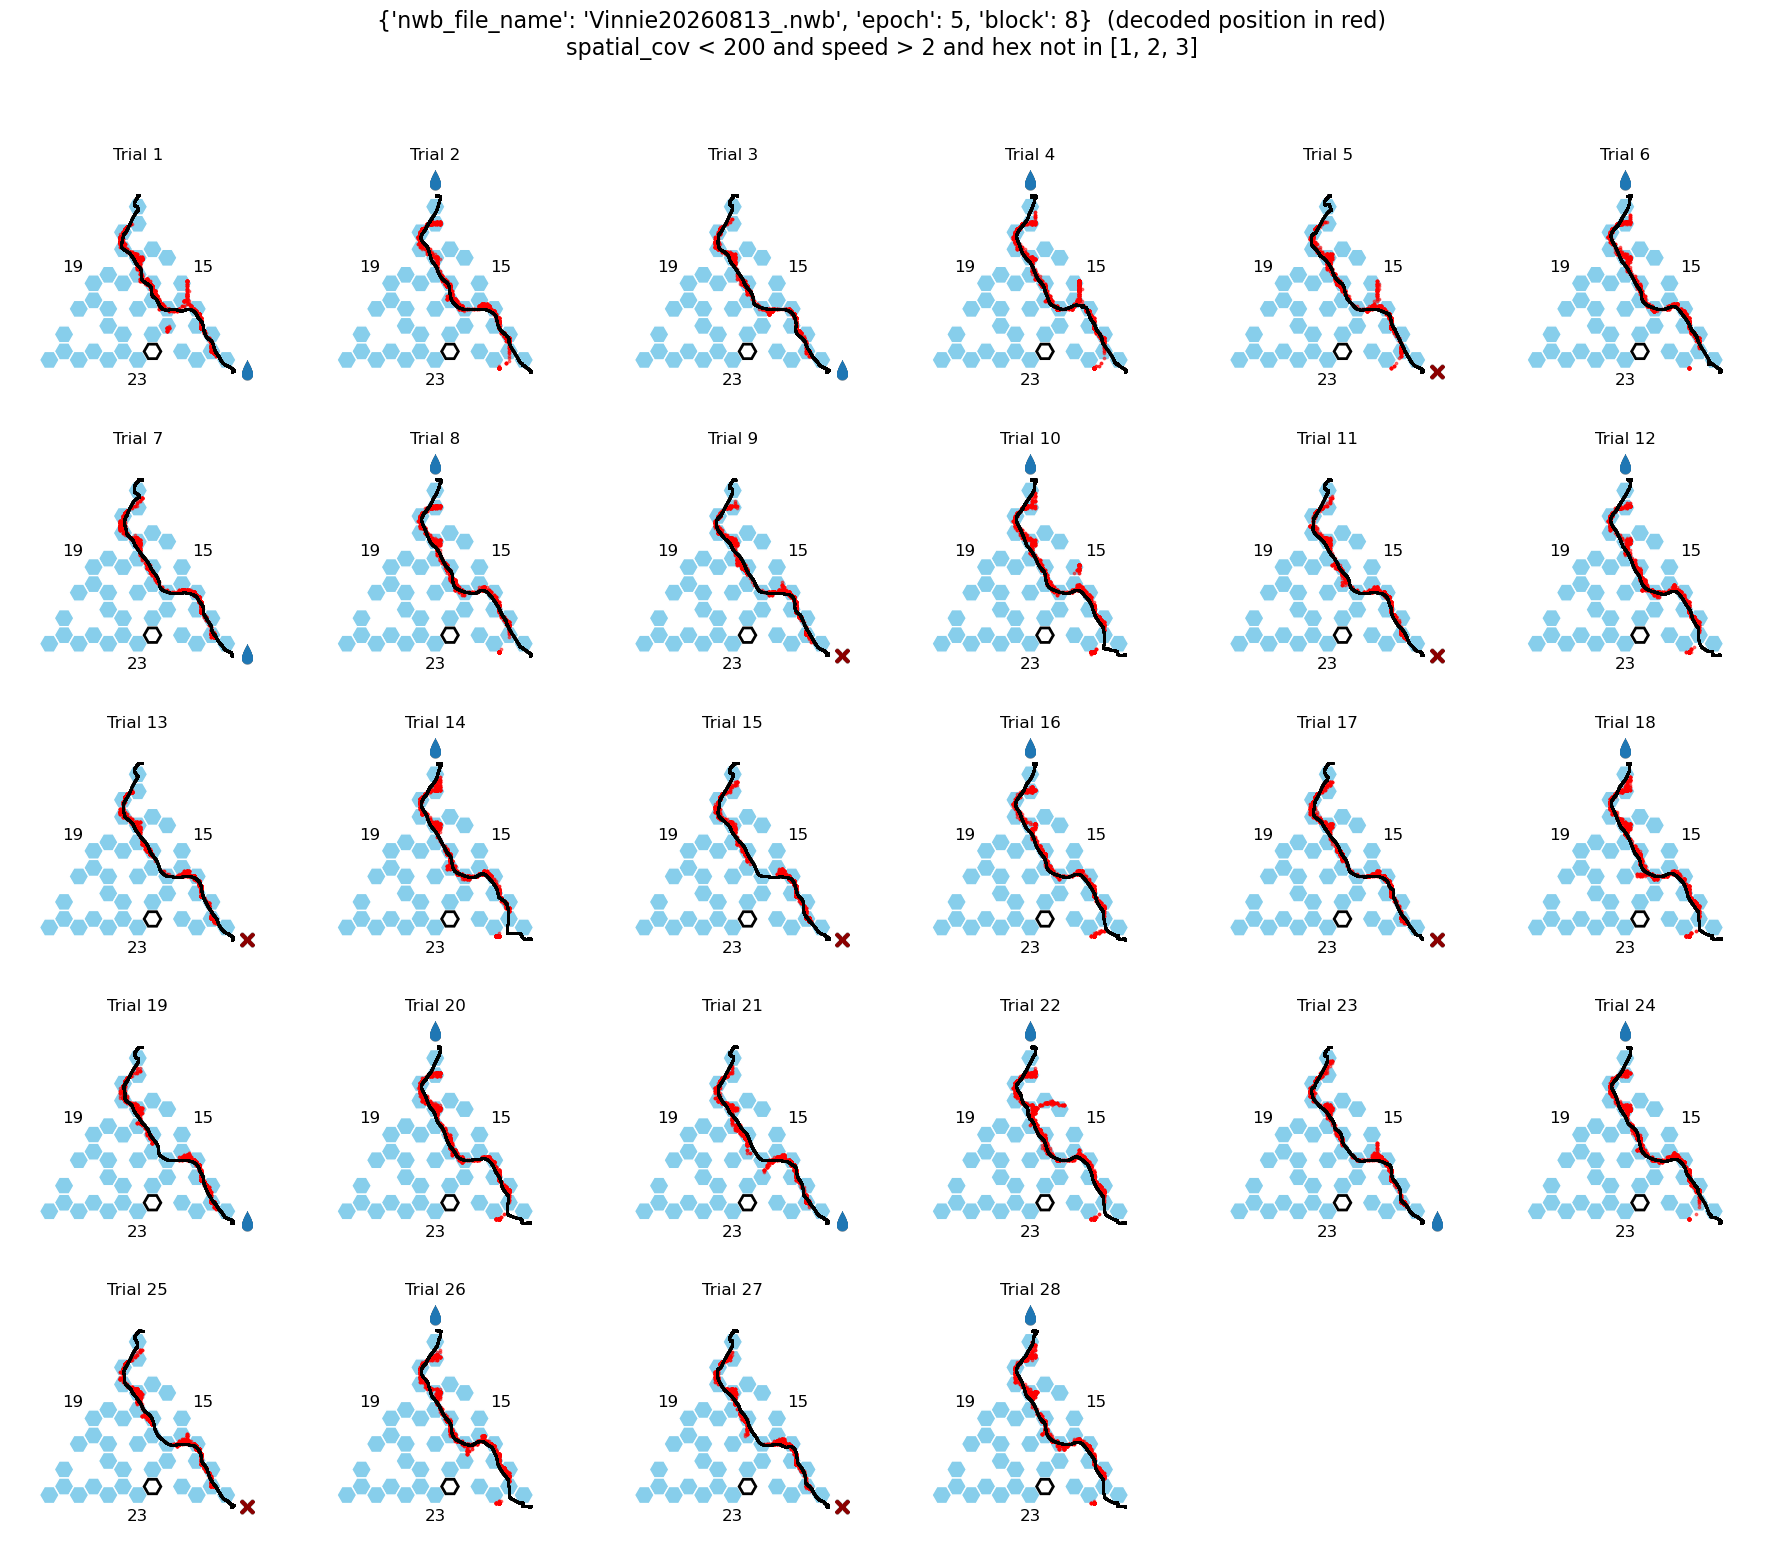

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 5, 'block': 9}: HexmazeNoStim
saved figures/ahead_behind/Vinnie20260813_ep5_block9_classic_d7c7a7.png


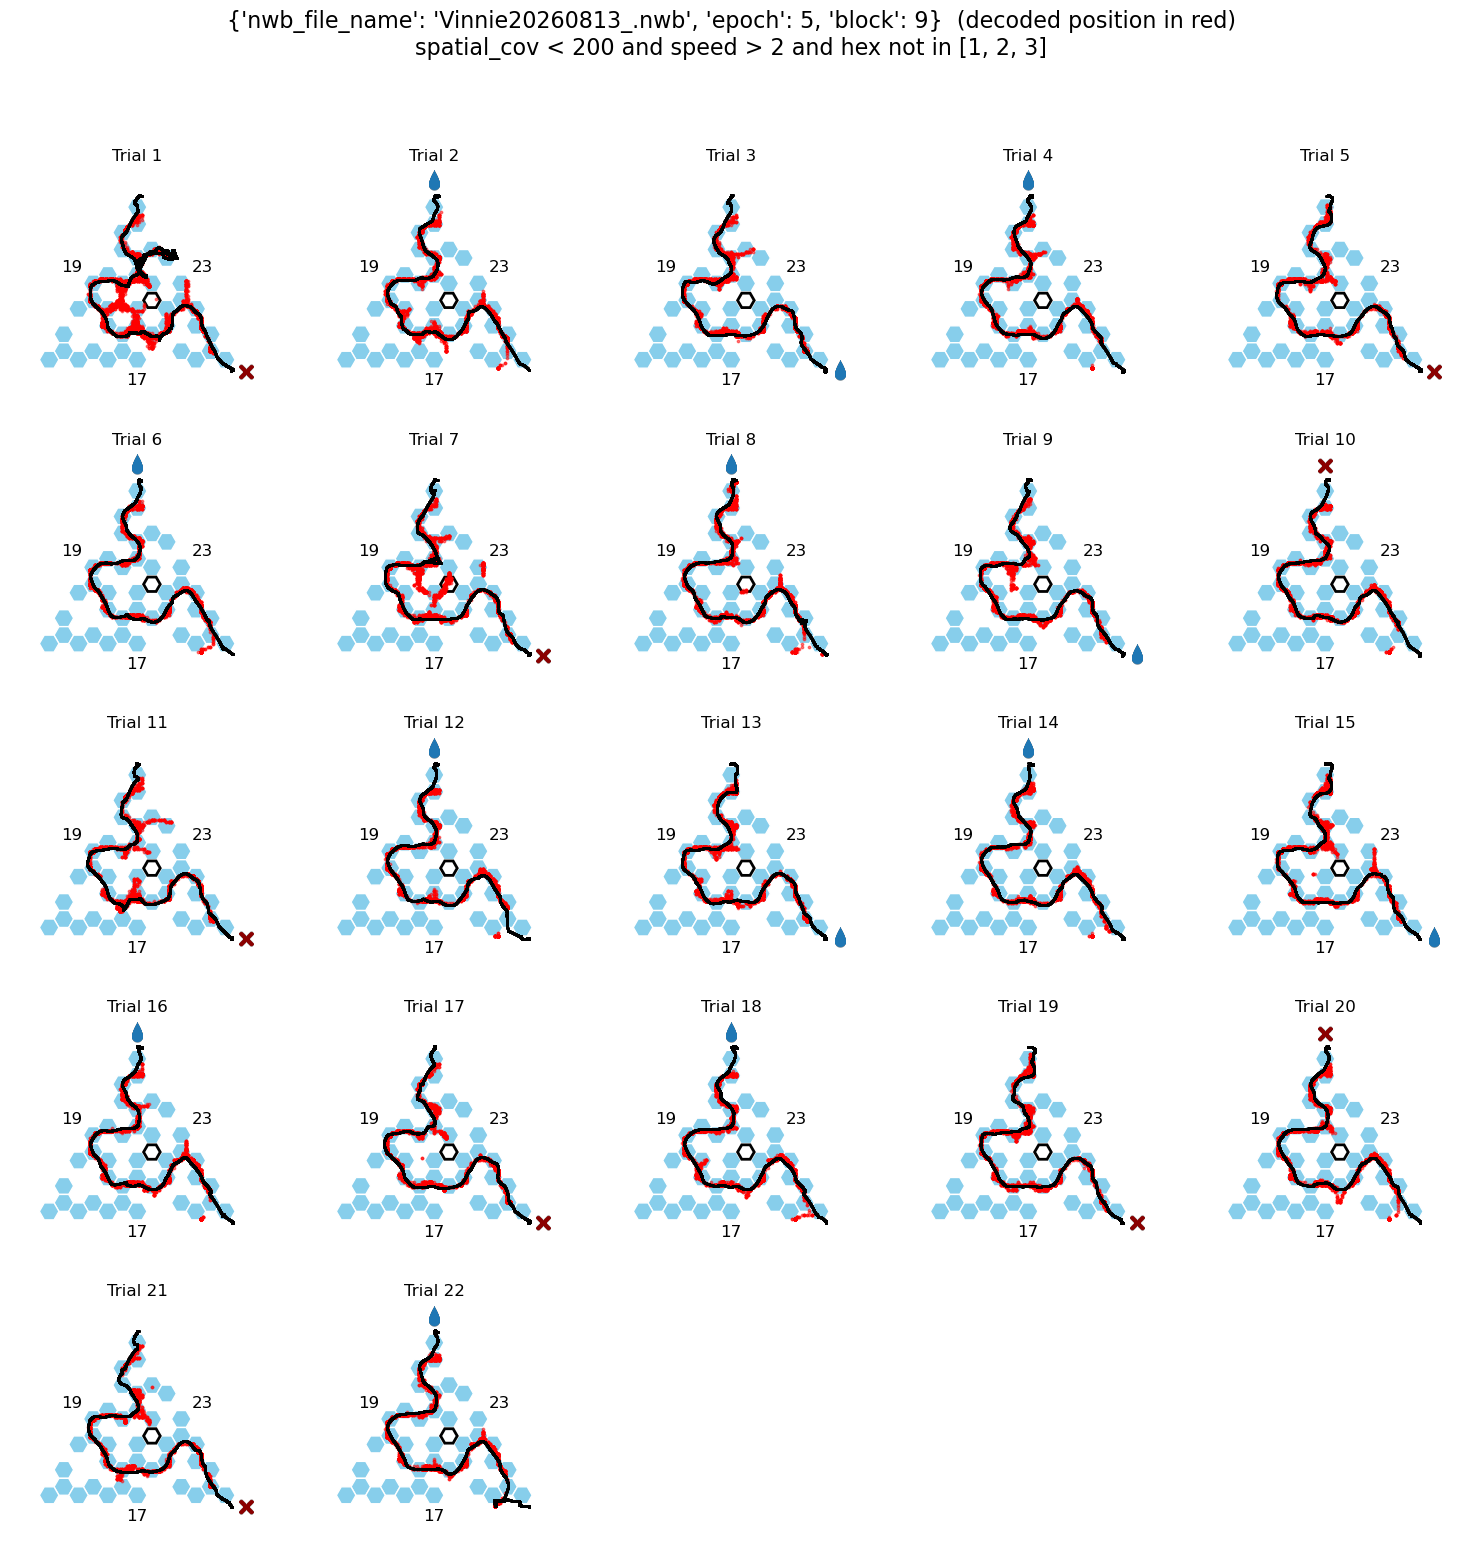

{'nwb_file_name': 'Vinnie20260813_.nwb', 'epoch': 7, 'block': 1}: HexmazeNoStim


/home/scrater/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/spec/namespace.py:484: UserWarning: Schema conflict(s) detected in namespace 'ndx-optogenetics': 
 ndx-optogenetics defines ExcitationSource.model as a link to ExcitationSourceModel while the core schema defines it as a link to DeviceModel. ExcitationSourceModel is not a subtype of DeviceModel. 
ndx-optogenetics defines OpticalFiber.model as a link to OpticalFiberModel while the core schema defines it as a link to DeviceModel. OpticalFiberModel is not a subtype of DeviceModel.  
This may cause compatibility issues. Please update the extension version if possible or install an older version of the core schema that is compatible.
  self._check_namespace_conflicts(extension_ns_name=ns_name,
/home/scrater/miniforge3/envs/spyglass/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/camera_device 0/model
  warnings.warn('Path to Group altere

In [ ]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable

from hexmaze import plot_hex_maze, maze_to_barrier_set

import spyglass.common as sgc
from spyglass_hexmaze.hex_maze_behavior import HexMazeBlock, HexCentroids
from spyglass_hexmaze.hex_maze_decoding import HexMazeDecodedPositionHex

# Pick a rat, session, etc. Empty means every populated epoch
restriction = "nwb_file_name LIKE 'Vinnie%'"   # {} for every session

# Get decode keys based on restriction
decode_keys = (HexMazeDecodedPositionHex() & restriction).fetch(
    "KEY", order_by="nwb_file_name, epoch")

## Which samples count. The same filter the barrier change notebooks use, without
## decode_in_maze, which only the barrier change table carries
decode_filter = "spatial_cov < 200 and speed > 2 and hex not in [1, 2, 3]"

CMAP_DIST = "coolwarm"      # blue = behind rat (negative), red = ahead (positive)

## Classic style: the default blue maze with every decoded point in red, 
# If classic is false, the maze is light green and decoded points are red/blue
# with saturation determined by ahead/behind distance
# On a barrier change block the hex that just became a barrier is outlined in black
CLASSIC_STYLE = True

FIGURE_ROOT = Path("figures") / "ahead_behind"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

## Every figure name carries the style and the filter it was made with, so a second run at
## other settings writes alongside the first instead of overwriting it
PARAMS_TAG = hashlib.md5(decode_filter.encode()).hexdigest()[:6]

# Loop through blocks 
for key in (HexMazeBlock() & decode_keys).fetch("KEY", order_by="nwb_file_name, epoch, block"):

    print(f"{key}: {(sgc.Session() & key).fetch('session_description')[0]}")
    block = HexMazeBlock() & key
    trials = HexMazeBlock.Trial() & key
    num_trials = len(trials)
    maze, p_a, p_b, p_c = block.fetch1("config_id", "p_a", "p_b", "p_c")
    centroids = HexCentroids().get_core_hex_centroids_dict_cm(key)

    pos_df = (HexMazeDecodedPositionHex() & key).fetch1_dataframe()

    # The hex that became a barrier with this block, against the block before it. The first
    # block of an epoch has nothing before it, so it gets no outline
    previous_block = (HexMazeBlock() & {k: key[k] for k in ("nwb_file_name", "epoch")}
                      & f"block = {key['block'] - 1}")
    now_blocked = (maze_to_barrier_set(maze) - maze_to_barrier_set(previous_block.fetch1("config_id"))
                   if previous_block else set())

    if CLASSIC_STYLE:
        # the default blue maze, with the barrier that just arrived outlined
        maze_kwargs = ({"outline_hexes": [now_blocked], "outline_colors": ["black"]}
                       if now_blocked else {})
    else:
        # tint all background hexes light green for contrast with the coolwarm decode points
        maze_kwargs = {"highlight_hexes": set(centroids), "highlight_colors": ["#90bd8f"]}

    # Points that pass the filter, used for both the color limit and the plotting
    good_samples = pos_df.query(decode_filter)
    # Symmetric color limit so 0 (rat's location) sits at the middle of the colormap.
    # Use the 95th percentile of |distance| so a few big outliers don't wash out the colors.
    absdist = good_samples["decode_distance"].abs()
    vlim = float(np.nanpercentile(absdist, 95)) if len(absdist) else 1.0
    vlim = max(vlim, 1e-3)                                  # guard against all-zero
    norm = TwoSlopeNorm(vcenter=0.0, vmin=-vlim, vmax=vlim)

    ncols = int(np.ceil(np.sqrt(num_trials)))
    nrows = int(np.ceil(num_trials / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = np.array([axes]).flatten() if isinstance(axes, plt.Axes) else np.array(axes).flatten()
    # What the points mean depends on the style, and the filter says which samples survived to
    # be drawn, so both belong in the title
    point_meaning = ("decoded position in red" if CLASSIC_STYLE
                     else "decoded position colored by distance from rat")
    fig.suptitle(f"{key}  ({point_meaning})\n{decode_filter}", fontsize=16, y=1.04)

    for i, trial_info in enumerate(trials):
        start, end = (sgc.IntervalList() & trial_info).fetch1("valid_times")[0]
        df_trial = pos_df.loc[start:end]

        axes[i].set_title(f"Trial {i+1}")
        plot_hex_maze(
            ax=axes[i], barriers=maze, centroids=centroids, snap_centroids=True,
            invert_yaxis=True, show_barriers=False, show_hex_labels=False,
            # Show a reward droplet (rewarded) or no-reward X (omission) at the port the rat chose
            show_stats=True, reward=(trial_info["end_port"], bool(trial_info["reward"])),
            **maze_kwargs,
        )

        # Decoded position: red in the classic style, otherwise colored by signed distance
        # from the rat (blue=behind, red=ahead)
        pred = df_trial.query(decode_filter)
        if CLASSIC_STYLE:
            axes[i].scatter(pred["decode_position_x"], pred["decode_position_y"],
                            s=3, color="red", alpha=0.5, zorder=2)
        else:
            axes[i].scatter(pred["decode_position_x"], pred["decode_position_y"],
                            c=pred["decode_distance"], cmap=CMAP_DIST, norm=norm, s=3,
                            alpha=0.5, zorder=2)
        # The rat's own position last and in black, so the trajectory stays readable on top of
        # however many decoded points landed on it
        axes[i].scatter(df_trial["position_x"], df_trial["position_y"], s=1, color="k", zorder=3)

    for j in range(num_trials, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    # Shared colorbar for the whole block, which the classic style has no use for
    if not CLASSIC_STYLE:
        sm = ScalarMappable(norm=norm, cmap=CMAP_DIST); sm.set_array([])
        fig.colorbar(sm, ax=axes.tolist(), shrink=0.6,
                     label="decode distance (cm;  <0 behind,  >0 ahead)")

    # Save as a png named for the block and the settings that drew it
    session_id = key["nwb_file_name"].replace("_.nwb", "")
    style = "classic" if CLASSIC_STYLE else "distance"
    fig_path = (FIGURE_ROOT / f"{session_id}_ep{key['epoch']}_block{key['block']}"
                              f"_{style}_{PARAMS_TAG}.png")
    fig.savefig(fig_path, dpi=300, facecolor="white", bbox_inches="tight")
    print(f"saved {fig_path}")
    plt.show()
